# Amsterdam Few-Shot Domain Adaptation

Assess how a model trained on Madrid transfers to Amsterdam with small amounts of labelled target-domain data. Methods include zero-shot prediction, prototype-based adaptation, frozen-model score calibration and target-domain SVM training.

**Inputs:** `features.pkl` and `final_model.pkl`.  
**Outputs:** per-episode results, method summaries, a few-shot leaderboard and saved selections for downstream analysis.

**Protocol:** repeated balanced support draws at 5, 25, 50, 100 and 200 labels per class. Model selection within an episode uses its support labels; query labels are reserved for evaluation. Spatial-buffer diagnostics are optional and depend on coordinate availability. The default experiment does not enable adaptation based on the full unlabelled target distribution.

---

## Notebook workflow


## Adaptation ladder

The notebook tests the cheapest and safest methods first.

### 1. Zero-shot source model

Apply the frozen Madrid model directly to all Amsterdam pixels.

This is the number every adaptation method must beat.

The notebook also compares this score with the Madrid source-validation score from model selection stage to quantify the source → target performance drop.

### 2. Source-score calibration

The frozen Madrid SVM produces four `decision_function` scores per Amsterdam pixel.

A small multinomial logistic regression is fitted **only on the Amsterdam support labels** to remap those four scores.

This is extremely cheap because the expensive Madrid SVM is not retrained.

### 3. Prototype methods

- Mean Prototype
- Median Prototype
- Madrid feature-weighted Prototype
- Madrid-shrinkage Prototype

Shrinkage strength is chosen from the support labels only.

### 4. Target-only RBF-SVM

A small Amsterdam RBF-SVM is trained only on the support pixels.

`C` and `gamma` are selected using support-only stratified CV.

### 5. Source SVM + HistGradientBoosting

A HistGradientBoosting source model is trained once on Madrid.

Its probabilities are averaged 50/50 with a softmax of the frozen Madrid SVM scores.

No expensive `probability=True` refit of the SVM is required.

### Optional / rule-dependent experiments

Two ideas use the complete **unlabelled Amsterdam feature distribution**:

- Amsterdam-specific standardization;
- identifying and removing features that strongly distinguish Madrid from Amsterdam.

They are disabled by default because the challenge rules should explicitly permit this type of target-distribution adaptation.

### Optional expensive experiment

Weighted Madrid + Amsterdam SVM retraining is included but disabled by default.

It can sweep Amsterdam sample weights and `C`, but it is computationally expensive because every run refits a large RBF-SVM.

In [41]:
# Imports and experiment configuration

from pathlib import Path
import gc
import json
import pickle
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial import cKDTree

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    f1_score,
    confusion_matrix,
    classification_report,
)
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")

SEED = 42

OFFICIAL_SHOTS = [
    5,
    25,
    50,
    100,
    200,
]

RUN_EXTRA_DIAGNOSTIC_SHOTS = False
EXTRA_DIAGNOSTIC_SHOTS = [
    10,
    20,
]

SHOTS_PER_CLASS = (
    sorted(
        set(
            OFFICIAL_SHOTS
            + (
                EXTRA_DIAGNOSTIC_SHOTS
                if RUN_EXTRA_DIAGNOSTIC_SHOTS
                else []
            )
        )
    )
)

N_TRIALS = 30

# ------------------------------------------------------------
# Spatial evaluation
# ------------------------------------------------------------

# Keep False unless the rules explicitly allow active support selection.
USE_SPATIALLY_SPREAD_SUPPORT = False

# Always attempt a buffered-query diagnostic when coordinates are available.
RUN_SPATIAL_BUFFER_DIAGNOSTIC = True

# Distance is measured in px_key / py_key coordinate units.
SPATIAL_BUFFER_RADIUS = 3.0

# ------------------------------------------------------------
# Rule-dependent target-distribution experiments
# ------------------------------------------------------------

# These methods use the complete unlabelled Amsterdam feature distribution.
# Enable only if challenge rules permit that.
ALLOW_UNLABELED_TARGET_ADAPTATION = False

SHIFT_FEATURES_TO_DROP = 15

# ------------------------------------------------------------
# Expensive Madrid + Amsterdam SVM retraining
# ------------------------------------------------------------

RUN_WEIGHTED_SOURCE_SVM = False

WEIGHTED_SVM_AMSTERDAM_WEIGHTS = [
    1.0,
    5.0,
    20.0,
    50.0,
]

WEIGHTED_SVM_C_GRID = [
    5.0,
    10.0,
]

# If the expensive sweep is enabled, start with at least 10 trials.
WEIGHTED_SVM_TRIALS = 10

# ------------------------------------------------------------
# Support-only tuning grids
# ------------------------------------------------------------

SHRINKAGE_K_GRID = [
    0.0,
    2.0,
    5.0,
    10.0,
    25.0,
    50.0,
    100.0,
]

TARGET_SVM_GRID = [
    {
        "C": 2.0,
        "gamma": "scale",
    },
    {
        "C": 10.0,
        "gamma": "scale",
    },
    {
        "C": 30.0,
        "gamma": "scale",
    },
    {
        "C": 10.0,
        "gamma": 0.01,
    },
]

KAGGLE_INPUT = Path(
    "/kaggle/input"
)

KAGGLE_WORKING = Path(
    "/kaggle/working"
)

OUTPUT_DIR = (
    KAGGLE_WORKING
    / "track_c"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print(
    "Official shot sizes:",
    OFFICIAL_SHOTS,
)

print(
    "All shot sizes in this run:",
    SHOTS_PER_CLASS,
)

print(
    "Trials per shot:",
    N_TRIALS,
)

print(
    "Spatial support selection:",
    USE_SPATIALLY_SPREAD_SUPPORT,
)

print(
    "Unlabelled-target adaptation enabled:",
    ALLOW_UNLABELED_TARGET_ADAPTATION,
)

print(
    "Weighted source-SVM sweep enabled:",
    RUN_WEIGHTED_SOURCE_SVM,
)

Official shot sizes: [5, 25, 50, 100, 200]
All shot sizes in this run: [5, 25, 50, 100, 200]
Trials per shot: 30
Spatial support selection: False
Unlabelled-target adaptation enabled: False
Weighted source-SVM sweep enabled: False


## 1. Find feature engineering stage and model selection stage outputs

Provide the output artifacts from feature engineering stage and model selection stage to this notebook.

Required:

```text
features.pkl
final_model.pkl
```

The notebook also looks for `selected_model.json` so it can recover model selection stage's Madrid confirmation score.

In [42]:
def find_file(
    filename,
    preferred_paths=None,
    required=True,
):
    preferred_paths = (
        preferred_paths
        if preferred_paths is not None
        else []
    )

    candidates = [
        Path(path)
        for path in preferred_paths
    ]

    if KAGGLE_INPUT.exists():
        candidates.extend(
            sorted(
                KAGGLE_INPUT.rglob(
                    filename
                )
            )
        )

    candidates.append(
        Path.cwd()
        / filename
    )

    valid = [
        path
        for path in candidates
        if path.exists()
    ]

    if valid:
        return valid[0]

    if required:
        raise FileNotFoundError(
            f"Could not find {filename}. "
            "Attach the saved output from the required previous track."
        )

    return None


FEATURES_PATH = find_file(
    "features.pkl",
    preferred_paths=[
        KAGGLE_WORKING
        / "track_a"
        / "features.pkl",
    ],
)

SOURCE_MODEL_PATH = find_file(
    "final_model.pkl",
    preferred_paths=[
        KAGGLE_WORKING
        / "track_b"
        / "final_model.pkl",
    ],
)

TRACK_B_SELECTION_PATH = (
    find_file(
        "selected_model.json",
        preferred_paths=[
            KAGGLE_WORKING
            / "track_b"
            / "selected_model.json",
        ],
        required=False,
    )
)

print(
    "Track A:",
    FEATURES_PATH,
)

print(
    "Track B model:",
    SOURCE_MODEL_PATH,
)

print(
    "Track B selection record:",
    TRACK_B_SELECTION_PATH,
)

Track A: /kaggle/working/track_a/features.pkl
Track B model: /kaggle/working/track_b/final_model.pkl
Track B selection record: /kaggle/working/track_b/selected_model.json


## 2. Load and validate the artifacts

In [43]:
with FEATURES_PATH.open(
    "rb"
) as f:
    data = pickle.load(
        f
    )

with SOURCE_MODEL_PATH.open(
    "rb"
) as f:
    source_bundle = pickle.load(
        f
    )

required_features = [
    "X_madrid",
    "X_amsterdam",
    "y_madrid",
    "y_amsterdam",
    "feature_names",
    "metadata",
]

missing = [
    key
    for key in required_features
    if key not in data
]

if missing:
    raise KeyError(
        f"Track A is missing: {missing}"
    )

required_source = [
    "model_name",
    "params",
    "model",
    "imputer",
    "scaler",
    "label_encoder",
    "feature_names",
]

missing_source = [
    key
    for key in required_source
    if key not in source_bundle
]

if missing_source:
    raise KeyError(
        f"Track B is missing: {missing_source}"
    )

X_madrid_raw = np.asarray(
    data[
        "X_madrid"
    ],
    dtype=np.float32,
)

X_amsterdam_raw = np.asarray(
    data[
        "X_amsterdam"
    ],
    dtype=np.float32,
)

y_madrid_original = np.asarray(
    data[
        "y_madrid"
    ]
).reshape(-1)

y_amsterdam_original = np.asarray(
    data[
        "y_amsterdam"
    ]
).reshape(-1)

feature_names = list(
    data[
        "feature_names"
    ]
)

if (
    list(
        source_bundle[
            "feature_names"
        ]
    )
    != feature_names
):
    raise ValueError(
        "Track A and Track B feature orders do not match."
    )

label_encoder = (
    source_bundle[
        "label_encoder"
    ]
)

y_madrid = (
    label_encoder.transform(
        y_madrid_original
    )
    .astype(
        np.int64
    )
)

y_amsterdam = (
    label_encoder.transform(
        y_amsterdam_original
    )
    .astype(
        np.int64
    )
)

CLASSES = np.arange(
    len(
        label_encoder.classes_
    ),
    dtype=np.int64,
)

pixel_ids_amsterdam = (
    np.asarray(
        data[
            "pixel_ids_amsterdam"
        ]
    )
    if (
        "pixel_ids_amsterdam"
        in data
    )
    else None
)

if (
    pixel_ids_amsterdam
    is not None
    and pixel_ids_amsterdam.ndim == 2
    and pixel_ids_amsterdam.shape[1] >= 2
):
    AMSTERDAM_COORDS = (
        pixel_ids_amsterdam[
            :,
            :2,
        ]
        .astype(
            np.float64
        )
    )
else:
    AMSTERDAM_COORDS = None

print(
    "Madrid features:",
    X_madrid_raw.shape,
)

print(
    "Amsterdam features:",
    X_amsterdam_raw.shape,
)

print(
    "Classes:",
    list(
        label_encoder.classes_
    ),
)

print(
    "Source model:",
    source_bundle[
        "model_name"
    ],
)

print(
    "Source params:",
    source_bundle[
        "params"
    ],
)

print(
    "Amsterdam coordinates available:",
    AMSTERDAM_COORDS
    is not None,
)

Madrid features: (76263, 126)
Amsterdam features: (25992, 126)
Classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Source model: RBF SVM
Source params: {'C': 10.0}
Amsterdam coordinates available: True


## 3. Recover the Madrid reference score

domain adaptation stage reports the Amsterdam zero-shot score together with the source-validation score from model selection stage.

That difference is a simple measure of the domain shift.

In [44]:
SOURCE_CV_F1_FALLBACK = (
    0.676815
)

SOURCE_CV_F1 = (
    SOURCE_CV_F1_FALLBACK
)

if (
    TRACK_B_SELECTION_PATH
    is not None
):
    with (
        TRACK_B_SELECTION_PATH
    ).open(
        "r",
        encoding="utf-8",
    ) as f:
        selection_record = (
            json.load(
                f
            )
        )

    for possible_key in [
        "confirmation_mean_macro_f1",
        "development_mean_macro_f1",
    ]:
        if (
            possible_key
            in selection_record
        ):
            SOURCE_CV_F1 = float(
                selection_record[
                    possible_key
                ]
            )
            break

print(
    "Madrid source-validation Macro-F1:",
    f"{SOURCE_CV_F1:.6f}",
)

Madrid source-validation Macro-F1: 0.676815


## 4. Amsterdam class balance and support-size checks

In [45]:
class_counts = (
    pd.Series(
        y_amsterdam_original
    )
    .value_counts()
    .sort_index()
)

class_props = (
    pd.Series(
        y_amsterdam_original
    )
    .value_counts(
        normalize=True
    )
    .sort_index()
)

class_balance = pd.DataFrame({
    "count": (
        class_counts
    ),
    "proportion": (
        class_props
    ),
})

display(
    class_balance
)

if (
    class_counts.min()
    <= max(
        SHOTS_PER_CLASS
    )
):
    raise ValueError(
        "At least one Amsterdam class does not contain "
        "enough pixels for the largest requested support size."
    )

class_balance.to_csv(
    OUTPUT_DIR
    / "class_balance.csv",
    index_label="class",
)

,count,proportion
1,7568,0.291167
2,8802,0.338643
3,6745,0.259503
4,2877,0.110688


## 5. Frozen Madrid preprocessing

The primary representation uses the imputer and scaler fitted on Madrid after model-selection model selection.

Amsterdam does **not** refit preprocessing in this primary path.

In [46]:
source_imputer = (
    source_bundle[
        "imputer"
    ]
)

source_scaler = (
    source_bundle[
        "scaler"
    ]
)

source_model = (
    source_bundle[
        "model"
    ]
)

X_madrid = (
    source_scaler.transform(
        source_imputer.transform(
            X_madrid_raw
        )
    )
    .astype(
        np.float32
    )
)

X_amsterdam = (
    source_scaler.transform(
        source_imputer.transform(
            X_amsterdam_raw
        )
    )
    .astype(
        np.float32
    )
)

assert np.isfinite(
    X_madrid
).all()

assert np.isfinite(
    X_amsterdam
).all()

if not hasattr(
    source_model,
    "decision_function",
):
    raise AttributeError(
        "The frozen Track-B source model does not expose decision_function(). "
        "Source-score calibration requires the selected SVM."
    )

print(
    "Frozen Madrid representation ready."
)

Frozen Madrid representation ready.


## 6. Zero-shot baseline and source → target drop

This is the anchor result.

The frozen Madrid model is scored on **all Amsterdam labels** without adaptation.

In [47]:
source_scores_all = np.asarray(
    source_model.decision_function(
        X_amsterdam
    ),
    dtype=np.float64,
)

if (
    source_scores_all.ndim
    != 2
    or source_scores_all.shape[1]
    != len(CLASSES)
):
    raise ValueError(
        "Expected one SVM decision score per class."
    )

zero_shot_pred = np.asarray(
    source_model.predict(
        X_amsterdam
    )
).reshape(-1).astype(
    np.int64
)

ZERO_SHOT_F1 = f1_score(
    y_amsterdam,
    zero_shot_pred,
    labels=CLASSES,
    average="macro",
    zero_division=0,
)

DOMAIN_SHIFT_DROP = (
    SOURCE_CV_F1
    - ZERO_SHOT_F1
)

print(
    "Madrid CV Macro-F1:",
    f"{SOURCE_CV_F1:.6f}",
)

print(
    "Amsterdam zero-shot Macro-F1:",
    f"{ZERO_SHOT_F1:.6f}",
)

print(
    "Source → target drop:",
    f"{DOMAIN_SHIFT_DROP:.6f}",
)

zero_shot_report = (
    pd.DataFrame(
        classification_report(
            y_amsterdam,
            zero_shot_pred,
            labels=CLASSES,
            target_names=[
                str(c)
                for c
                in label_encoder.classes_
            ],
            output_dict=True,
            zero_division=0,
        )
    )
    .T
)

display(
    zero_shot_report
)

zero_shot_report.to_csv(
    OUTPUT_DIR
    / "zero_shot_classification_report.csv"
)

Madrid CV Macro-F1: 0.676815
Amsterdam zero-shot Macro-F1: 0.394313
Source → target drop: 0.282501


,precision,recall,f1-score,support
1,0.569264,0.670058,0.615562,7568.000000
2,0.454287,0.290729,0.354555,8802.000000
3,0.666269,0.165456,0.265083,6745.000000
4,0.221358,0.752172,0.342053,2877.000000
accuracy,0.419745,0.419745,0.419745,0.419745
macro avg,0.477794,0.469604,0.394313,25992.000000
weighted avg,0.516992,0.419745,0.405949,25992.000000


## 7. Spatial support sampling helper

This helper is only used when:

```python
USE_SPATIALLY_SPREAD_SUPPORT = True
```

It performs randomized farthest-point sampling within each class.

The first point is random; subsequent points favour candidates farther from the already selected support points.

In [48]:
def spatially_spread_sample(
    class_indices,
    coords,
    n_shots,
    rng,
):
    class_indices = np.asarray(
        class_indices,
        dtype=np.int64,
    )

    if n_shots >= len(
        class_indices
    ):
        return class_indices.copy()

    # Restrict the candidate pool so the optional spatial mode stays cheap.
    candidate_count = min(
        len(class_indices),
        max(
            10 * n_shots,
            500,
        ),
    )

    candidate_idx = rng.choice(
        class_indices,
        size=candidate_count,
        replace=False,
    )

    candidate_coords = coords[
        candidate_idx
    ]

    first_local = int(
        rng.integers(
            0,
            candidate_count,
        )
    )

    selected_local = [
        first_local
    ]

    min_d2 = np.sum(
        (
            candidate_coords
            - candidate_coords[
                first_local
            ]
        ) ** 2,
        axis=1,
    )

    min_d2[
        first_local
    ] = -np.inf

    for _ in range(
        1,
        n_shots,
    ):
        next_local = int(
            np.argmax(
                min_d2
            )
        )

        selected_local.append(
            next_local
        )

        new_d2 = np.sum(
            (
                candidate_coords
                - candidate_coords[
                    next_local
                ]
            ) ** 2,
            axis=1,
        )

        min_d2 = np.minimum(
            min_d2,
            new_d2,
        )

        min_d2[
            selected_local
        ] = -np.inf

    return candidate_idx[
        np.asarray(
            selected_local,
            dtype=np.int64,
        )
    ]

## 8. Build fixed few-shot episodes

All methods use the same episodes.

Random balanced sampling remains the default.

If spatial support selection is explicitly permitted by the challenge, switch the configuration flag at the top.

In [49]:
episodes = {}

for n_shots in SHOTS_PER_CLASS:
    episodes[
        n_shots
    ] = []

    for trial in range(
        N_TRIALS
    ):
        rng = (
            np.random.default_rng(
                SEED
                + 10_000
                * n_shots
                + trial
            )
        )

        support_parts = []

        for cls in CLASSES:
            cls_idx = (
                np.flatnonzero(
                    y_amsterdam
                    == cls
                )
            )

            if (
                USE_SPATIALLY_SPREAD_SUPPORT
            ):
                if (
                    AMSTERDAM_COORDS
                    is None
                ):
                    raise ValueError(
                        "Spatial support sampling was requested "
                        "but Amsterdam coordinates are unavailable."
                    )

                chosen = (
                    spatially_spread_sample(
                        cls_idx,
                        AMSTERDAM_COORDS,
                        n_shots,
                        rng,
                    )
                )

            else:
                chosen = rng.choice(
                    cls_idx,
                    size=n_shots,
                    replace=False,
                )

            support_parts.append(
                chosen
            )

        support_idx = (
            np.concatenate(
                support_parts
            )
            .astype(
                np.int32
            )
        )

        rng.shuffle(
            support_idx
        )

        query_mask = np.ones(
            len(
                y_amsterdam
            ),
            dtype=bool,
        )

        query_mask[
            support_idx
        ] = False

        query_idx = (
            np.flatnonzero(
                query_mask
            )
            .astype(
                np.int32
            )
        )

        if (
            len(
                np.intersect1d(
                    support_idx,
                    query_idx,
                )
            )
            != 0
        ):
            raise RuntimeError(
                "Support/query overlap detected."
            )

        episodes[
            n_shots
        ].append({
            "trial": trial,
            "support_idx": (
                support_idx
            ),
            "query_idx": (
                query_idx
            ),
        })

for n_shots in SHOTS_PER_CLASS:
    first = (
        episodes[
            n_shots
        ][0]
    )

    print(
        f"{n_shots:3d}/class | "
        f"support={len(first['support_idx']):4d} | "
        f"query={len(first['query_idx']):5d} | "
        f"trials={N_TRIALS}"
    )

with (
    OUTPUT_DIR
    / "episodes.pkl"
).open(
    "wb"
) as f:
    pickle.dump(
        episodes,
        f,
        protocol=pickle.HIGHEST_PROTOCOL,
    )

  5/class | support=  20 | query=25972 | trials=30
 25/class | support= 100 | query=25892 | trials=30
 50/class | support= 200 | query=25792 | trials=30
100/class | support= 400 | query=25592 | trials=30
200/class | support= 800 | query=25192 | trials=30


## 9. Spatially buffered query diagnostic

For every episode, the notebook optionally identifies query pixels whose nearest support pixel is at least:

```text
SPATIAL_BUFFER_RADIUS
```

coordinate-key units away.

This does **not** replace the official query score.

It is an additional diagnostic for checking whether performance collapses when nearby support/query neighbours are removed.

In [50]:
def spatial_query_mask(
    support_idx,
    query_idx,
):
    if (
        not RUN_SPATIAL_BUFFER_DIAGNOSTIC
        or AMSTERDAM_COORDS
        is None
    ):
        return None

    tree = cKDTree(
        AMSTERDAM_COORDS[
            support_idx
        ]
    )

    nearest_distance, _ = (
        tree.query(
            AMSTERDAM_COORDS[
                query_idx
            ],
            k=1,
        )
    )

    return (
        nearest_distance
        >= SPATIAL_BUFFER_RADIUS
    )


if (
    RUN_SPATIAL_BUFFER_DIAGNOSTIC
    and AMSTERDAM_COORDS
    is not None
):
    example = (
        episodes[
            OFFICIAL_SHOTS[0]
        ][0]
    )

    mask = spatial_query_mask(
        example[
            "support_idx"
        ],
        example[
            "query_idx"
        ],
    )

    print(
        "Example spatially buffered query size:",
        int(
            mask.sum()
        ),
        "/",
        len(mask),
    )
else:
    print(
        "Spatial buffered-query diagnostic unavailable/disabled."
    )

Example spatially buffered query size: 25833 / 25972


## 10. Madrid feature weights

The feature-weighted prototype uses a Fisher-style discriminativeness score computed from Madrid labels only.

In [51]:
def compute_fisher_weights(
    X,
    y,
):
    overall = X.mean(
        axis=0
    )

    between = np.zeros(
        X.shape[1],
        dtype=np.float64,
    )

    within = np.zeros(
        X.shape[1],
        dtype=np.float64,
    )

    for cls in CLASSES:
        Xc = X[
            y == cls
        ]

        mean_c = Xc.mean(
            axis=0
        )

        between += (
            len(Xc)
            * (
                mean_c
                - overall
            ) ** 2
        )

        within += (
            (
                Xc
                - mean_c
            ) ** 2
        ).sum(
            axis=0
        )

    fisher = (
        between
        / (
            within
            + 1e-8
        )
    )

    upper = np.quantile(
        fisher,
        0.99,
    )

    fisher = np.clip(
        fisher,
        0,
        upper,
    )

    weights = np.sqrt(
        fisher
        + 1e-12
    )

    weights /= (
        weights.mean()
        + 1e-12
    )

    return weights.astype(
        np.float32
    )


FEATURE_WEIGHTS = (
    compute_fisher_weights(
        X_madrid,
        y_madrid,
    )
)

feature_weights_df = (
    pd.DataFrame({
        "feature": (
            feature_names
        ),
        "weight": (
            FEATURE_WEIGHTS
        ),
    })
    .sort_values(
        "weight",
        ascending=False,
    )
)

display(
    feature_weights_df.head(
        20
    )
)

feature_weights_df.to_csv(
    OUTPUT_DIR
    / "feature_weights.csv",
    index=False,
)

,feature,weight
25,NIR_early_mean,2.231287
77,NIR_mean_2000s,2.231287
76,NIR_mean_1990s,2.187156
3,NIR_mean,2.152984
75,NIR_mean_1984_1989,1.737731
37,NIR_late_mean,1.726212
82,SWIR1_mean_2000s,1.616269
101,UI_mean_1990s,1.609395
21,BSI_std,1.583418
78,NIR_mean_2010s,1.558979


## 11. Madrid class prototypes

In [52]:
MADRID_PROTOTYPES = {
    cls: (
        X_madrid[
            y_madrid == cls
        ]
        .mean(
            axis=0
        )
    )
    for cls in CLASSES
}

## 12. Prototype helpers

In [53]:
def build_prototypes(
    X_support,
    y_support,
    statistic="mean",
):
    prototypes = {}

    for cls in CLASSES:
        Xc = X_support[
            y_support == cls
        ]

        if statistic == "mean":
            proto = Xc.mean(
                axis=0
            )

        elif statistic == "median":
            proto = np.median(
                Xc,
                axis=0,
            )

        else:
            raise ValueError(
                statistic
            )

        prototypes[
            cls
        ] = proto

    return prototypes


def predict_from_prototypes(
    X_query,
    prototypes,
    weights=None,
):
    proto_matrix = np.stack(
        [
            prototypes[
                cls
            ]
            for cls
            in CLASSES
        ]
    )

    diff = (
        X_query[
            :,
            None,
            :,
        ]
        - proto_matrix[
            None,
            :,
            :,
        ]
    )

    if weights is None:
        d2 = (
            diff ** 2
        ).sum(
            axis=2
        )

    else:
        d2 = (
            (
                diff ** 2
            )
            * weights[
                None,
                None,
                :,
            ]
        ).sum(
            axis=2
        )

    return CLASSES[
        np.argmin(
            d2,
            axis=1,
        )
    ]


def mean_prototype_predict(
    X_support,
    y_support,
    X_query,
):
    return predict_from_prototypes(
        X_query,
        build_prototypes(
            X_support,
            y_support,
            "mean",
        ),
    )


def median_prototype_predict(
    X_support,
    y_support,
    X_query,
):
    return predict_from_prototypes(
        X_query,
        build_prototypes(
            X_support,
            y_support,
            "median",
        ),
    )


def weighted_prototype_predict(
    X_support,
    y_support,
    X_query,
):
    return predict_from_prototypes(
        X_query,
        build_prototypes(
            X_support,
            y_support,
            "mean",
        ),
        weights=FEATURE_WEIGHTS,
    )

## 13. Support-only shrinkage prototypes

The shrinkage parameter `k` is selected without Amsterdam query labels.

Leave-one-out predictions are generated inside the support set, and the `k` with the strongest support-only Macro-F1 is used.

In [54]:
def build_shrinkage_prototypes(
    X_support,
    y_support,
    k,
):
    result = {}

    for cls in CLASSES:
        Xc = X_support[
            y_support == cls
        ]

        n_cls = len(
            Xc
        )

        target_proto = Xc.mean(
            axis=0
        )

        alpha = (
            1.0
            if k == 0
            else (
                n_cls
                / (
                    n_cls
                    + k
                )
            )
        )

        result[
            cls
        ] = (
            alpha
            * target_proto
            + (
                1.0
                - alpha
            )
            * MADRID_PROTOTYPES[
                cls
            ]
        )

    return result


def choose_shrinkage_k(
    X_support,
    y_support,
):
    candidates = []

    for k in SHRINKAGE_K_GRID:
        pred = np.empty(
            len(
                y_support
            ),
            dtype=np.int64,
        )

        for i in range(
            len(
                y_support
            )
        ):
            keep = np.ones(
                len(
                    y_support
                ),
                dtype=bool,
            )

            keep[
                i
            ] = False

            prototypes = (
                build_shrinkage_prototypes(
                    X_support[
                        keep
                    ],
                    y_support[
                        keep
                    ],
                    k,
                )
            )

            pred[
                i
            ] = (
                predict_from_prototypes(
                    X_support[
                        i:i+1
                    ],
                    prototypes,
                )[0]
            )

        score = f1_score(
            y_support,
            pred,
            labels=CLASSES,
            average="macro",
            zero_division=0,
        )

        candidates.append(
            (
                float(
                    score
                ),
                float(
                    k
                ),
            )
        )

    candidates.sort(
        key=lambda x: (
            -x[0],
            x[1],
        )
    )

    return candidates[
        0
    ][1]


def shrinkage_predict(
    X_support,
    y_support,
    X_query,
):
    best_k = (
        choose_shrinkage_k(
            X_support,
            y_support,
        )
    )

    prototypes = (
        build_shrinkage_prototypes(
            X_support,
            y_support,
            best_k,
        )
    )

    pred = (
        predict_from_prototypes(
            X_query,
            prototypes,
        )
    )

    return (
        pred,
        best_k,
    )

## 14. Calibrate the frozen SVM scores on Amsterdam support labels

The expensive Madrid SVM stays frozen.

Only a small logistic regression on its four output scores is fitted for each support episode.

Because the support sets are balanced by construction, this should be interpreted primarily as **target-domain score remapping / boundary calibration**, not as a perfect estimate of Amsterdam class priors.

In [55]:
def calibrated_source_predict(
    support_idx,
    query_idx,
):
    support_scores = (
        source_scores_all[
            support_idx
        ]
    )

    query_scores = (
        source_scores_all[
            query_idx
        ]
    )

    calibrator = (
        LogisticRegression(
            C=1.0,
            solver="lbfgs",
            max_iter=2000,
            random_state=SEED,
        )
    )

    calibrator.fit(
        support_scores,
        y_amsterdam[
            support_idx
        ],
    )

    return np.asarray(
        calibrator.predict(
            query_scores
        )
    ).reshape(-1).astype(
        np.int64
    )

## 15. Support-only target RBF-SVM tuning

In [56]:
def choose_target_svm_params(
    X_support,
    y_support,
):
    min_class_count = int(
        pd.Series(
            y_support
        )
        .value_counts()
        .min()
    )

    n_splits = min(
        5,
        min_class_count,
    )

    inner_cv = (
        StratifiedKFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=SEED,
        )
    )

    rows = []

    for params in TARGET_SVM_GRID:
        scores = []

        for (
            train_idx,
            valid_idx,
        ) in inner_cv.split(
            X_support,
            y_support,
        ):
            model = SVC(
                C=params[
                    "C"
                ],
                gamma=params[
                    "gamma"
                ],
                kernel="rbf",
                class_weight="balanced",
                probability=False,
                cache_size=1024,
            )

            model.fit(
                X_support[
                    train_idx
                ],
                y_support[
                    train_idx
                ],
            )

            pred = model.predict(
                X_support[
                    valid_idx
                ]
            )

            scores.append(
                f1_score(
                    y_support[
                        valid_idx
                    ],
                    pred,
                    labels=CLASSES,
                    average="macro",
                    zero_division=0,
                )
            )

        rows.append({
            "params": (
                params
            ),
            "mean_f1": float(
                np.mean(
                    scores
                )
            ),
            "sd_f1": float(
                np.std(
                    scores
                )
            ),
        })

    rows.sort(
        key=lambda row: (
            -row[
                "mean_f1"
            ],
            row[
                "sd_f1"
            ],
        )
    )

    return rows[
        0
    ]["params"]


def target_svm_predict(
    X_support,
    y_support,
    X_query,
):
    best_params = (
        choose_target_svm_params(
            X_support,
            y_support,
        )
    )

    model = SVC(
        C=best_params[
            "C"
        ],
        gamma=best_params[
            "gamma"
        ],
        kernel="rbf",
        class_weight="balanced",
        probability=False,
        cache_size=1024,
    )

    model.fit(
        X_support,
        y_support,
    )

    pred = np.asarray(
        model.predict(
            X_query
        )
    ).reshape(-1).astype(
        np.int64
    )

    return (
        pred,
        best_params,
    )

## 16. Source SVM + HistGradientBoosting ensemble

model selection stage selected the RBF-SVM because it was strongest on Madrid.

A second source model may degrade differently under city shift, so domain adaptation stage trains one HistGradientBoosting model on all Madrid.

The ensemble uses:

```text
0.5 × softmax(SVM decision scores)
+
0.5 × HistGradientBoosting probabilities
```

The 50/50 weight is fixed before Amsterdam evaluation.

In [57]:
def softmax_scores(
    scores,
):
    scores = np.asarray(
        scores,
        dtype=np.float64,
    )

    shifted = (
        scores
        - scores.max(
            axis=1,
            keepdims=True,
        )
    )

    exp_scores = np.exp(
        shifted
    )

    return (
        exp_scores
        / exp_scores.sum(
            axis=1,
            keepdims=True,
        )
    )


hgb_source = (
    HistGradientBoostingClassifier(
        learning_rate=0.07,
        max_iter=220,
        max_leaf_nodes=63,
        l2_regularization=2.0,
        random_state=SEED,
    )
)

madrid_sample_weight = (
    compute_sample_weight(
        class_weight="balanced",
        y=y_madrid,
    )
)

hgb_source.fit(
    X_madrid,
    y_madrid,
    sample_weight=(
        madrid_sample_weight
    ),
)

hgb_amsterdam_proba = (
    hgb_source.predict_proba(
        X_amsterdam
    )
)

svm_amsterdam_softmax = (
    softmax_scores(
        source_scores_all
    )
)

ensemble_proba = (
    0.5
    * svm_amsterdam_softmax
    + 0.5
    * hgb_amsterdam_proba
)

source_ensemble_pred = (
    CLASSES[
        np.argmax(
            ensemble_proba,
            axis=1,
        )
    ]
)

SOURCE_ENSEMBLE_F1 = (
    f1_score(
        y_amsterdam,
        source_ensemble_pred,
        labels=CLASSES,
        average="macro",
        zero_division=0,
    )
)

print(
    "Source SVM + HGB zero-shot Macro-F1:",
    f"{SOURCE_ENSEMBLE_F1:.6f}",
)

Source SVM + HGB zero-shot Macro-F1: 0.458305


## 17. Optional: Amsterdam-specific standardization

This experiment uses the complete unlabelled Amsterdam feature distribution.

It is therefore disabled unless:

```python
ALLOW_UNLABELED_TARGET_ADAPTATION = True
```

Only enable it if the challenge rules permit using the full target feature distribution for adaptation.

In [58]:
TARGET_SCALED_PRED = None
TARGET_SCALED_F1 = np.nan

if (
    ALLOW_UNLABELED_TARGET_ADAPTATION
):
    target_imputer = (
        SimpleImputer(
            strategy="median",
        )
    )

    X_target_imp = (
        target_imputer.fit_transform(
            X_amsterdam_raw
        )
    )

    target_scaler = (
        StandardScaler()
    )

    X_amsterdam_target_scaled = (
        target_scaler.fit_transform(
            X_target_imp
        )
        .astype(
            np.float32
        )
    )

    TARGET_SCALED_PRED = (
        np.asarray(
            source_model.predict(
                X_amsterdam_target_scaled
            )
        )
        .reshape(-1)
        .astype(
            np.int64
        )
    )

    TARGET_SCALED_F1 = (
        f1_score(
            y_amsterdam,
            TARGET_SCALED_PRED,
            labels=CLASSES,
            average="macro",
            zero_division=0,
        )
    )

    print(
        "Amsterdam-standardized zero-shot F1:",
        f"{TARGET_SCALED_F1:.6f}",
    )

else:
    print(
        "Amsterdam-specific standardization skipped."
    )

Amsterdam-specific standardization skipped.


## 18. Optional: detect and remove shift-prone features

This also uses the complete unlabelled Amsterdam feature distribution.

A city classifier is trained to distinguish Madrid from Amsterdam.

The most important city-discriminating features are treated as potentially shift-prone.

If enabled, one new Madrid RBF-SVM is trained after dropping the top `SHIFT_FEATURES_TO_DROP` features and then evaluated zero-shot on Amsterdam.

This is a diagnostic hypothesis, not a guaranteed improvement.

In [59]:
SHIFT_ABLATION_PRED = None
SHIFT_ABLATION_F1 = np.nan
SHIFT_KEEP_MASK = None

if (
    ALLOW_UNLABELED_TARGET_ADAPTATION
):
    rng = (
        np.random.default_rng(
            SEED
        )
    )

    n_city = min(
        len(
            X_madrid
        ),
        len(
            X_amsterdam
        ),
    )

    madrid_city_idx = (
        rng.choice(
            len(
                X_madrid
            ),
            size=n_city,
            replace=False,
        )
    )

    amsterdam_city_idx = (
        rng.choice(
            len(
                X_amsterdam
            ),
            size=n_city,
            replace=False,
        )
    )

    X_city = np.vstack([
        X_madrid[
            madrid_city_idx
        ],
        X_amsterdam[
            amsterdam_city_idx
        ],
    ])

    y_city = np.concatenate([
        np.zeros(
            n_city,
            dtype=np.int64,
        ),
        np.ones(
            n_city,
            dtype=np.int64,
        ),
    ])

    city_model = (
        RandomForestClassifier(
            n_estimators=300,
            max_depth=20,
            class_weight="balanced",
            random_state=SEED,
            n_jobs=-1,
        )
    )

    city_model.fit(
        X_city,
        y_city,
    )

    shift_table = (
        pd.DataFrame({
            "feature": (
                feature_names
            ),
            "importance": (
                city_model.feature_importances_
            ),
            "feature_index": (
                np.arange(
                    len(
                        feature_names
                    )
                )
            ),
        })
        .sort_values(
            "importance",
            ascending=False,
        )
        .reset_index(
            drop=True
        )
    )

    display(
        shift_table.head(
            25
        )
    )

    shift_table.to_csv(
        OUTPUT_DIR
        / "domain_shift_features.csv",
        index=False,
    )

    drop_indices = (
        shift_table.head(
            SHIFT_FEATURES_TO_DROP
        )[
            "feature_index"
        ]
        .to_numpy(
            dtype=np.int64
        )
    )

    SHIFT_KEEP_MASK = np.ones(
        len(
            feature_names
        ),
        dtype=bool,
    )

    SHIFT_KEEP_MASK[
        drop_indices
    ] = False

    source_c = float(
        source_bundle[
            "params"
        ].get(
            "C",
            10.0,
        )
    )

    shift_model = SVC(
        C=source_c,
        kernel="rbf",
        gamma="scale",
        class_weight="balanced",
        probability=False,
        cache_size=2048,
    )

    shift_model.fit(
        X_madrid[
            :,
            SHIFT_KEEP_MASK,
        ],
        y_madrid,
    )

    SHIFT_ABLATION_PRED = (
        np.asarray(
            shift_model.predict(
                X_amsterdam[
                    :,
                    SHIFT_KEEP_MASK,
                ]
            )
        )
        .reshape(-1)
        .astype(
            np.int64
        )
    )

    SHIFT_ABLATION_F1 = (
        f1_score(
            y_amsterdam,
            SHIFT_ABLATION_PRED,
            labels=CLASSES,
            average="macro",
            zero_division=0,
        )
    )

    print(
        "Shift-feature ablation zero-shot F1:",
        f"{SHIFT_ABLATION_F1:.6f}",
    )

else:
    print(
        "Shift-feature diagnostic/ablation skipped."
    )

Shift-feature diagnostic/ablation skipped.


## 19. Result-recording helper

In addition to Macro-F1, this stores:

- per-class F1 for every episode;
- spatially buffered Macro-F1;
- spatially buffered per-class F1;
- number of spatially buffered query pixels retained.

In [60]:
result_rows = []
class_rows = []


def record_result(
    *,
    method,
    n_shots,
    trial,
    y_query,
    pred,
    spatial_mask,
    selected_k=np.nan,
    selected_C=np.nan,
    selected_gamma="",
    amsterdam_weight=np.nan,
):
    macro = f1_score(
        y_query,
        pred,
        labels=CLASSES,
        average="macro",
        zero_division=0,
    )

    per_class = f1_score(
        y_query,
        pred,
        labels=CLASSES,
        average=None,
        zero_division=0,
    )

    spatial_macro = np.nan
    spatial_per_class = (
        np.full(
            len(CLASSES),
            np.nan,
            dtype=float,
        )
    )
    n_spatial = 0

    if (
        spatial_mask
        is not None
        and spatial_mask.sum()
        > 0
    ):
        y_spatial = (
            y_query[
                spatial_mask
            ]
        )

        pred_spatial = (
            pred[
                spatial_mask
            ]
        )

        spatial_macro = (
            f1_score(
                y_spatial,
                pred_spatial,
                labels=CLASSES,
                average="macro",
                zero_division=0,
            )
        )

        spatial_per_class = (
            f1_score(
                y_spatial,
                pred_spatial,
                labels=CLASSES,
                average=None,
                zero_division=0,
            )
        )

        n_spatial = int(
            spatial_mask.sum()
        )

    result_rows.append({
        "method": method,
        "n_shots": int(
            n_shots
        ),
        "trial": int(
            trial
        ),
        "macro_f1": float(
            macro
        ),
        "spatial_macro_f1": (
            float(
                spatial_macro
            )
            if np.isfinite(
                spatial_macro
            )
            else np.nan
        ),
        "n_query": int(
            len(
                y_query
            )
        ),
        "n_spatial_query": (
            n_spatial
        ),
        "selected_k": (
            selected_k
        ),
        "selected_C": (
            selected_C
        ),
        "selected_gamma": (
            selected_gamma
        ),
        "amsterdam_weight": (
            amsterdam_weight
        ),
    })

    for j, cls in enumerate(
        CLASSES
    ):
        class_rows.append({
            "method": (
                method
            ),
            "n_shots": int(
                n_shots
            ),
            "trial": int(
                trial
            ),
            "class": (
                label_encoder.inverse_transform(
                    [
                        cls
                    ]
                )[0]
            ),
            "f1": float(
                per_class[
                    j
                ]
            ),
            "spatial_f1": (
                float(
                    spatial_per_class[
                        j
                    ]
                )
                if np.isfinite(
                    spatial_per_class[
                        j
                    ]
                )
                else np.nan
            ),
        })

## 20. Main Amsterdam few-shot benchmark

This is the default domain-adaptation benchmark.

It does **not** run the expensive Madrid + Amsterdam SVM weight sweep.

In [61]:
benchmark_start = (
    time.perf_counter()
)

for n_shots in SHOTS_PER_CLASS:
    print(
        "\n"
        + "=" * 78
    )

    print(
        f"{n_shots} LABELS PER CLASS"
    )

    print(
        "=" * 78
    )

    for episode in episodes[
        n_shots
    ]:
        trial = episode[
            "trial"
        ]

        support_idx = episode[
            "support_idx"
        ]

        query_idx = episode[
            "query_idx"
        ]

        X_support = (
            X_amsterdam[
                support_idx
            ]
        )

        y_support = (
            y_amsterdam[
                support_idx
            ]
        )

        X_query = (
            X_amsterdam[
                query_idx
            ]
        )

        y_query = (
            y_amsterdam[
                query_idx
            ]
        )

        spatial_mask = (
            spatial_query_mask(
                support_idx,
                query_idx,
            )
        )

        # ------------------------------------------------
        # Zero-shot frozen source
        # ------------------------------------------------
        record_result(
            method=(
                "Zero-shot source"
            ),
            n_shots=n_shots,
            trial=trial,
            y_query=y_query,
            pred=zero_shot_pred[
                query_idx
            ],
            spatial_mask=(
                spatial_mask
            ),
        )

        # ------------------------------------------------
        # Calibrated source scores
        # ------------------------------------------------
        calibrated_pred = (
            calibrated_source_predict(
                support_idx,
                query_idx,
            )
        )

        record_result(
            method=(
                "Calibrated source"
            ),
            n_shots=n_shots,
            trial=trial,
            y_query=y_query,
            pred=(
                calibrated_pred
            ),
            spatial_mask=(
                spatial_mask
            ),
        )

        # ------------------------------------------------
        # Mean prototype
        # ------------------------------------------------
        pred = (
            mean_prototype_predict(
                X_support,
                y_support,
                X_query,
            )
        )

        record_result(
            method=(
                "Mean Prototype"
            ),
            n_shots=n_shots,
            trial=trial,
            y_query=y_query,
            pred=pred,
            spatial_mask=(
                spatial_mask
            ),
        )

        # ------------------------------------------------
        # Median prototype
        # ------------------------------------------------
        pred = (
            median_prototype_predict(
                X_support,
                y_support,
                X_query,
            )
        )

        record_result(
            method=(
                "Median Prototype"
            ),
            n_shots=n_shots,
            trial=trial,
            y_query=y_query,
            pred=pred,
            spatial_mask=(
                spatial_mask
            ),
        )

        # ------------------------------------------------
        # Madrid-weighted prototype
        # ------------------------------------------------
        pred = (
            weighted_prototype_predict(
                X_support,
                y_support,
                X_query,
            )
        )

        record_result(
            method=(
                "Weighted Prototype"
            ),
            n_shots=n_shots,
            trial=trial,
            y_query=y_query,
            pred=pred,
            spatial_mask=(
                spatial_mask
            ),
        )

        # ------------------------------------------------
        # Shrinkage prototype
        # ------------------------------------------------
        (
            pred,
            best_k,
        ) = shrinkage_predict(
            X_support,
            y_support,
            X_query,
        )

        record_result(
            method=(
                "Shrinkage Prototype"
            ),
            n_shots=n_shots,
            trial=trial,
            y_query=y_query,
            pred=pred,
            spatial_mask=(
                spatial_mask
            ),
            selected_k=(
                best_k
            ),
        )

        # ------------------------------------------------
        # Target-only RBF-SVM
        # ------------------------------------------------
        (
            pred,
            svm_params,
        ) = target_svm_predict(
            X_support,
            y_support,
            X_query,
        )

        record_result(
            method=(
                "Target RBF-SVM"
            ),
            n_shots=n_shots,
            trial=trial,
            y_query=y_query,
            pred=pred,
            spatial_mask=(
                spatial_mask
            ),
            selected_C=float(
                svm_params[
                    "C"
                ]
            ),
            selected_gamma=str(
                svm_params[
                    "gamma"
                ]
            ),
        )

        # ------------------------------------------------
        # Frozen source SVM + source HGB
        # ------------------------------------------------
        record_result(
            method=(
                "Source SVM + HGB"
            ),
            n_shots=n_shots,
            trial=trial,
            y_query=y_query,
            pred=(
                source_ensemble_pred[
                    query_idx
                ]
            ),
            spatial_mask=(
                spatial_mask
            ),
        )

        # ------------------------------------------------
        # Optional rule-dependent target distribution methods
        # ------------------------------------------------
        if (
            TARGET_SCALED_PRED
            is not None
        ):
            record_result(
                method=(
                    "Target-standardized source"
                ),
                n_shots=n_shots,
                trial=trial,
                y_query=y_query,
                pred=(
                    TARGET_SCALED_PRED[
                        query_idx
                    ]
                ),
                spatial_mask=(
                    spatial_mask
                ),
            )

        if (
            SHIFT_ABLATION_PRED
            is not None
        ):
            record_result(
                method=(
                    "Shift-feature ablation"
                ),
                n_shots=n_shots,
                trial=trial,
                y_query=y_query,
                pred=(
                    SHIFT_ABLATION_PRED[
                        query_idx
                    ]
                ),
                spatial_mask=(
                    spatial_mask
                ),
            )

        if (
            trial
            + 1
        ) % 5 == 0:
            print(
                f"Completed "
                f"{trial + 1}/"
                f"{N_TRIALS} trials"
            )

results = pd.DataFrame(
    result_rows
)

class_results = (
    pd.DataFrame(
        class_rows
    )
)

results.to_csv(
    OUTPUT_DIR
    / "episode_results.csv",
    index=False,
)

class_results.to_csv(
    OUTPUT_DIR
    / "per_class_episode_results.csv",
    index=False,
)

print(
    "\nDefault benchmark time:",
    round(
        (
            time.perf_counter()
            - benchmark_start
        )
        / 60.0,
        2,
    ),
    "minutes",
)


5 LABELS PER CLASS
Completed 5/30 trials
Completed 10/30 trials
Completed 15/30 trials
Completed 20/30 trials
Completed 25/30 trials
Completed 30/30 trials

25 LABELS PER CLASS
Completed 5/30 trials
Completed 10/30 trials
Completed 15/30 trials
Completed 20/30 trials
Completed 25/30 trials
Completed 30/30 trials

50 LABELS PER CLASS
Completed 5/30 trials
Completed 10/30 trials
Completed 15/30 trials
Completed 20/30 trials
Completed 25/30 trials
Completed 30/30 trials

100 LABELS PER CLASS
Completed 5/30 trials
Completed 10/30 trials
Completed 15/30 trials
Completed 20/30 trials
Completed 25/30 trials
Completed 30/30 trials

200 LABELS PER CLASS
Completed 5/30 trials
Completed 10/30 trials
Completed 15/30 trials
Completed 20/30 trials
Completed 25/30 trials
Completed 30/30 trials

Default benchmark time: 3.21 minutes


## 21. Optional expensive Madrid + weighted Amsterdam SVM sweep

This section is disabled by default.

If enabled, it retrains the Madrid RBF-SVM after adding the current Amsterdam support set with a larger sample weight.

Grid:

```text
Amsterdam weight: 1, 5, 20, 50
C:                5, 10
```

Because this is expensive, only the first `WEIGHTED_SVM_TRIALS` episodes per shot size are run.

Treat this as a finalist experiment, not the first thing to run.

In [62]:
def weighted_source_svm_predict(
    X_support,
    y_support,
    X_query,
    *,
    C,
    amsterdam_weight,
):
    X_train = np.vstack([
        X_madrid,
        X_support,
    ])

    y_train = np.concatenate([
        y_madrid,
        y_support,
    ])

    source_weights = (
        compute_sample_weight(
            class_weight="balanced",
            y=y_madrid,
        )
        .astype(
            np.float64
        )
    )

    target_weights = np.full(
        len(
            y_support
        ),
        float(
            amsterdam_weight
        ),
        dtype=np.float64,
    )

    sample_weight = (
        np.concatenate([
            source_weights,
            target_weights,
        ])
    )

    model = SVC(
        C=float(
            C
        ),
        kernel="rbf",
        gamma="scale",
        class_weight=None,
        probability=False,
        cache_size=2048,
    )

    model.fit(
        X_train,
        y_train,
        sample_weight=(
            sample_weight
        ),
    )

    return (
        np.asarray(
            model.predict(
                X_query
            )
        )
        .reshape(-1)
        .astype(
            np.int64
        )
    )


if RUN_WEIGHTED_SOURCE_SVM:
    weighted_rows_before = (
        len(
            result_rows
        )
    )

    for n_shots in SHOTS_PER_CLASS:
        for episode in (
            episodes[
                n_shots
            ][
                :WEIGHTED_SVM_TRIALS
            ]
        ):
            trial = episode[
                "trial"
            ]

            support_idx = episode[
                "support_idx"
            ]

            query_idx = episode[
                "query_idx"
            ]

            X_support = (
                X_amsterdam[
                    support_idx
                ]
            )

            y_support = (
                y_amsterdam[
                    support_idx
                ]
            )

            X_query = (
                X_amsterdam[
                    query_idx
                ]
            )

            y_query = (
                y_amsterdam[
                    query_idx
                ]
            )

            spatial_mask = (
                spatial_query_mask(
                    support_idx,
                    query_idx,
                )
            )

            for C in (
                WEIGHTED_SVM_C_GRID
            ):
                for weight in (
                    WEIGHTED_SVM_AMSTERDAM_WEIGHTS
                ):
                    print(
                        f"{n_shots}/class | "
                        f"trial={trial} | "
                        f"C={C} | "
                        f"Amsterdam weight={weight}"
                    )

                    pred = (
                        weighted_source_svm_predict(
                            X_support,
                            y_support,
                            X_query,
                            C=C,
                            amsterdam_weight=(
                                weight
                            ),
                        )
                    )

                    record_result(
                        method=(
                            f"Weighted source SVM "
                            f"C={C} W={weight}"
                        ),
                        n_shots=n_shots,
                        trial=trial,
                        y_query=y_query,
                        pred=pred,
                        spatial_mask=(
                            spatial_mask
                        ),
                        selected_C=(
                            C
                        ),
                        amsterdam_weight=(
                            weight
                        ),
                    )

                    gc.collect()

    results = pd.DataFrame(
        result_rows
    )

    class_results = (
        pd.DataFrame(
            class_rows
        )
    )

    results.to_csv(
        OUTPUT_DIR
        / "episode_results.csv",
        index=False,
    )

    class_results.to_csv(
        OUTPUT_DIR
        / "per_class_episode_results.csv",
        index=False,
    )

    print(
        "Weighted source-SVM rows added:",
        len(
            result_rows
        )
        - weighted_rows_before,
    )

else:
    print(
        "Weighted source-SVM sweep skipped."
    )

Weighted source-SVM sweep skipped.


## 22. Main mean ± SD summary

In [63]:
summary = (
    results
    .groupby(
        [
            "method",
            "n_shots",
        ]
    )[
        [
            "macro_f1",
            "spatial_macro_f1",
        ]
    ]
    .agg(
        [
            "mean",
            "std",
            "count",
        ]
    )
)

summary.columns = [
    "_".join(
        col
    )
    for col in summary.columns
]

summary = (
    summary
    .reset_index()
    .sort_values(
        [
            "n_shots",
            "macro_f1_mean",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)

display(
    summary
)

summary.to_csv(
    OUTPUT_DIR
    / "summary.csv",
    index=False,
)

,method,n_shots,macro_f1_mean,macro_f1_std,macro_f1_count,spatial_macro_f1_mean,spatial_macro_f1_std,spatial_macro_f1_count
0,Source SVM + HGB,5,0.458267,0.000089,30,0.457975,0.000446,30
1,Target RBF-SVM,5,0.448071,0.052321,30,0.446554,0.052284,30
2,Median Prototype,5,0.406337,0.068441,30,0.405363,0.068476,30
3,Zero-shot source,5,0.394268,0.000094,30,0.393964,0.000505,30
4,Calibrated source,5,0.370752,0.040907,30,0.370153,0.040786,30
5,Shrinkage Prototype,5,0.344106,0.038191,30,0.343703,0.038317,30
6,Weighted Prototype,5,0.298787,0.077509,30,0.297932,0.077453,30
7,Mean Prototype,5,0.283589,0.079011,30,0.282769,0.078942,30
8,Target RBF-SVM,25,0.595044,0.024285,30,0.590326,0.024513,30
9,Median Prototype,25,0.463414,0.036952,30,0.461467,0.036737,30


## 23. Per-class mean ± SD

This is the honest class-level breakdown across **all repeated episodes**, not one convenient example.

In [64]:
per_class_summary = (
    class_results
    .groupby(
        [
            "method",
            "n_shots",
            "class",
        ]
    )[
        [
            "f1",
            "spatial_f1",
        ]
    ]
    .agg(
        [
            "mean",
            "std",
            "count",
        ]
    )
)

per_class_summary.columns = [
    "_".join(
        col
    )
    for col in (
        per_class_summary.columns
    )
]

per_class_summary = (
    per_class_summary
    .reset_index()
)

display(
    per_class_summary
)

per_class_summary.to_csv(
    OUTPUT_DIR
    / "per_class_summary.csv",
    index=False,
)

,method,n_shots,class,f1_mean,f1_std,f1_count,spatial_f1_mean,spatial_f1_std,spatial_f1_count
0,Calibrated source,5,1,0.538766,0.107035,30,0.538492,0.106938,30
1,Calibrated source,5,2,0.279952,0.127896,30,0.279726,0.127918,30
2,Calibrated source,5,3,0.397018,0.092692,30,0.396517,0.092547,30
3,Calibrated source,5,4,0.267274,0.084061,30,0.265876,0.083980,30
4,Calibrated source,25,1,0.586836,0.058852,30,0.585117,0.058861,30
...,...,...,...,...,...,...,...,...,...
155,Zero-shot source,100,4,0.337487,0.000540,30,0.317903,0.004420,30
156,Zero-shot source,200,1,0.615454,0.000598,30,0.604299,0.004116,30
157,Zero-shot source,200,2,0.355267,0.000807,30,0.359547,0.004339,30
158,Zero-shot source,200,3,0.265159,0.001127,30,0.263017,0.005839,30


## 24. Few-shot method comparison

Only the formal challenge budgets are used for the main leaderboard.

Optional 10/20-shot diagnostic runs do not affect the ranking.

In [65]:
official_summary = (
    summary[
        summary[
            "n_shots"
        ].isin(
            OFFICIAL_SHOTS
        )
    ]
    .copy()
)

few_shot_official = (
    official_summary[
        official_summary[
            "method"
        ]
        != "Zero-shot source"
    ]
    .copy()
)

leaderboard = (
    few_shot_official
    .groupby(
        "method"
    )
    .agg(
        average_f1=(
            "macro_f1_mean",
            "mean",
        ),
        average_sd=(
            "macro_f1_std",
            "mean",
        ),
        peak_mean_f1=(
            "macro_f1_mean",
            "max",
        ),
        average_spatial_f1=(
            "spatial_macro_f1_mean",
            "mean",
        ),
    )
    .reset_index()
)

shot25 = (
    few_shot_official[
        few_shot_official[
            "n_shots"
        ] == 25
    ][
        [
            "method",
            "macro_f1_mean",
            "macro_f1_std",
            "spatial_macro_f1_mean",
        ]
    ]
    .rename(
        columns={
            "macro_f1_mean": (
                "f1_25"
            ),
            "macro_f1_std": (
                "sd_25"
            ),
            "spatial_macro_f1_mean": (
                "spatial_f1_25"
            ),
        }
    )
)

leaderboard = (
    leaderboard
    .merge(
        shot25,
        on="method",
        how="left",
    )
    .sort_values(
        "average_f1",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)

display(
    leaderboard
)

leaderboard.to_csv(
    OUTPUT_DIR
    / "leaderboard.csv",
    index=False,
)

,method,average_f1,average_sd,peak_mean_f1,average_spatial_f1,f1_25,sd_25,spatial_f1_25
0,Target RBF-SVM,0.609838,0.022239,0.699773,0.600705,0.595044,0.024285,0.590326
1,Median Prototype,0.463920,0.030186,0.488094,0.458862,0.463414,0.036952,0.461467
2,Source SVM + HGB,0.457517,0.000257,0.458267,0.452846,0.458073,0.000178,0.456493
3,Calibrated source,0.397235,0.021762,0.408411,0.392242,0.393863,0.030313,0.391820
4,Shrinkage Prototype,0.287146,0.037116,0.344106,0.283543,0.311873,0.036960,0.310493
5,Weighted Prototype,0.258258,0.054910,0.298787,0.254453,0.274510,0.063459,0.272739
6,Mean Prototype,0.239907,0.054491,0.283589,0.236336,0.255751,0.062363,0.254031


## 25. F1 versus labels per class

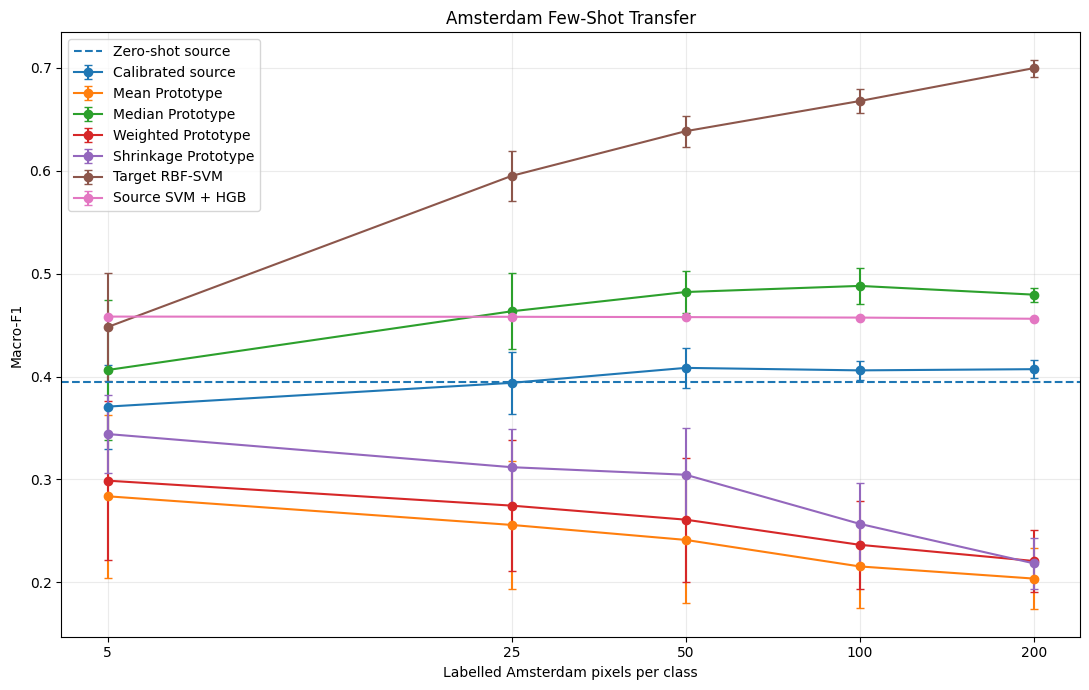

In [66]:
plot_methods = [
    method
    for method in [
        "Calibrated source",
        "Mean Prototype",
        "Median Prototype",
        "Weighted Prototype",
        "Shrinkage Prototype",
        "Target RBF-SVM",
        "Source SVM + HGB",
    ]
    if method
    in set(
        summary[
            "method"
        ]
    )
]

fig, ax = plt.subplots(
    figsize=(
        11,
        7,
    )
)

for method in plot_methods:
    part = (
        summary[
            (
                summary[
                    "method"
                ]
                == method
            )
            & (
                summary[
                    "n_shots"
                ].isin(
                    OFFICIAL_SHOTS
                )
            )
        ]
        .sort_values(
            "n_shots"
        )
    )

    ax.errorbar(
        part[
            "n_shots"
        ],
        part[
            "macro_f1_mean"
        ],
        yerr=part[
            "macro_f1_std"
        ],
        marker="o",
        capsize=3,
        label=method,
    )

ax.axhline(
    ZERO_SHOT_F1,
    linestyle="--",
    label=(
        "Zero-shot source"
    ),
)

ax.set_xscale(
    "log",
    base=2,
)

ax.set_xticks(
    OFFICIAL_SHOTS
)

ax.set_xticklabels(
    [
        str(
            x
        )
        for x in (
            OFFICIAL_SHOTS
        )
    ]
)

ax.set_xlabel(
    "Labelled Amsterdam pixels per class"
)

ax.set_ylabel(
    "Macro-F1"
)

ax.set_title(
    "Amsterdam Few-Shot Transfer"
)

ax.grid(
    alpha=0.25
)

ax.legend()

plt.tight_layout()

plot_path = (
    OUTPUT_DIR
    / "few_shot_results.png"
)

plt.savefig(
    plot_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 26. Spatially buffered performance

If coordinates are available, this table compares the ordinary query score with the score after removing query pixels close to the support set.

A large drop is evidence that random-pixel evaluation may be benefiting from local spatial similarity.

In [67]:
if (
    RUN_SPATIAL_BUFFER_DIAGNOSTIC
    and AMSTERDAM_COORDS
    is not None
):
    spatial_summary = (
        official_summary[
            [
                "method",
                "n_shots",
                "macro_f1_mean",
                "macro_f1_std",
                "spatial_macro_f1_mean",
                "spatial_macro_f1_std",
                "spatial_macro_f1_count",
            ]
        ]
        .copy()
    )

    spatial_summary[
        "spatial_drop"
    ] = (
        spatial_summary[
            "macro_f1_mean"
        ]
        - spatial_summary[
            "spatial_macro_f1_mean"
        ]
    )

    display(
        spatial_summary
    )

    spatial_summary.to_csv(
        OUTPUT_DIR
        / "spatial_buffer_summary.csv",
        index=False,
    )

else:
    print(
        "Spatial buffered-query summary unavailable."
    )

,method,n_shots,macro_f1_mean,macro_f1_std,spatial_macro_f1_mean,spatial_macro_f1_std,spatial_macro_f1_count,spatial_drop
0,Source SVM + HGB,5,0.458267,0.000089,0.457975,0.000446,30,0.000292
1,Target RBF-SVM,5,0.448071,0.052321,0.446554,0.052284,30,0.001516
2,Median Prototype,5,0.406337,0.068441,0.405363,0.068476,30,0.000974
3,Zero-shot source,5,0.394268,0.000094,0.393964,0.000505,30,0.000305
4,Calibrated source,5,0.370752,0.040907,0.370153,0.040786,30,0.000600
5,Shrinkage Prototype,5,0.344106,0.038191,0.343703,0.038317,30,0.000403
6,Weighted Prototype,5,0.298787,0.077509,0.297932,0.077453,30,0.000855
7,Mean Prototype,5,0.283589,0.079011,0.282769,0.078942,30,0.000821
8,Target RBF-SVM,25,0.595044,0.024285,0.590326,0.024513,30,0.004719
9,Median Prototype,25,0.463414,0.036952,0.461467,0.036737,30,0.001947


## 27. Support-only tuning behaviour

These tables show the parameters chosen **without query-label tuning**.

In [68]:
shrinkage_choices = (
    results[
        results[
            "method"
        ]
        == "Shrinkage Prototype"
    ]
    .groupby(
        [
            "n_shots",
            "selected_k",
        ]
    )
    .size()
    .rename(
        "count"
    )
    .reset_index()
)

svm_choices = (
    results[
        results[
            "method"
        ]
        == "Target RBF-SVM"
    ]
    .groupby(
        [
            "n_shots",
            "selected_C",
            "selected_gamma",
        ]
    )
    .size()
    .rename(
        "count"
    )
    .reset_index()
)

display(
    shrinkage_choices
)

display(
    svm_choices
)

shrinkage_choices.to_csv(
    OUTPUT_DIR
    / "shrinkage_choices.csv",
    index=False,
)

svm_choices.to_csv(
    OUTPUT_DIR
    / "target_svm_choices.csv",
    index=False,
)

,n_shots,selected_k,count
0,5,0.0,4
1,5,5.0,3
2,5,25.0,1
3,5,50.0,5
4,5,100.0,17
5,25,0.0,3
6,25,10.0,1
7,25,25.0,1
8,25,50.0,1
9,25,100.0,24


,n_shots,selected_C,selected_gamma,count
0,5,2.0,scale,2
1,5,10.0,0.01,12
2,5,10.0,scale,11
3,5,30.0,scale,5
4,25,2.0,scale,1
5,25,10.0,0.01,12
6,25,10.0,scale,3
7,25,30.0,scale,14
8,50,10.0,0.01,8
9,50,10.0,scale,5


## 28. Final domain-adaptation decision summary

The JSON records:

- Madrid source score;
- Amsterdam zero-shot score;
- measured domain-shift drop;
- best average few-shot method;
- best 25-shot method;
- best peak method;
- spatial-buffer diagnostic availability.

The final selection is based only on the formal 5/25/50/100/200-shot budgets.

In [69]:
best_average = (
    leaderboard.iloc[
        0
    ]
)

best_25 = (
    leaderboard
    .sort_values(
        "f1_25",
        ascending=False,
    )
    .iloc[
        0
    ]
)

best_peak = (
    leaderboard
    .sort_values(
        "peak_mean_f1",
        ascending=False,
    )
    .iloc[
        0
    ]
)

decision = {
    "source_model": (
        source_bundle[
            "model_name"
        ]
    ),
    "source_params": (
        source_bundle[
            "params"
        ]
    ),
    "madrid_source_cv_macro_f1": (
        float(
            SOURCE_CV_F1
        )
    ),
    "amsterdam_zero_shot_macro_f1": (
        float(
            ZERO_SHOT_F1
        )
    ),
    "source_to_target_drop": (
        float(
            DOMAIN_SHIFT_DROP
        )
    ),
    "official_shot_sizes": (
        OFFICIAL_SHOTS
    ),
    "trials_per_shot": (
        N_TRIALS
    ),
    "support_sampling": (
        "spatially_spread"
        if USE_SPATIALLY_SPREAD_SUPPORT
        else "random_balanced"
    ),
    "best_average_method": (
        str(
            best_average[
                "method"
            ]
        )
    ),
    "best_average_f1": (
        float(
            best_average[
                "average_f1"
            ]
        )
    ),
    "best_25_shot_method": (
        str(
            best_25[
                "method"
            ]
        )
    ),
    "best_25_shot_f1": (
        float(
            best_25[
                "f1_25"
            ]
        )
    ),
    "best_peak_method": (
        str(
            best_peak[
                "method"
            ]
        )
    ),
    "best_peak_mean_f1": (
        float(
            best_peak[
                "peak_mean_f1"
            ]
        )
    ),
    "spatial_buffer_diagnostic": (
        bool(
            RUN_SPATIAL_BUFFER_DIAGNOSTIC
            and AMSTERDAM_COORDS
            is not None
        )
    ),
    "unlabelled_target_adaptation_used": (
        bool(
            ALLOW_UNLABELED_TARGET_ADAPTATION
        )
    ),
}

with (
    OUTPUT_DIR
    / "transfer_summary.json"
).open(
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        decision,
        f,
        indent=2,
    )

print(
    json.dumps(
        decision,
        indent=2,
    )
)

{
  "source_model": "RBF SVM",
  "source_params": {
    "C": 10.0
  },
  "madrid_source_cv_macro_f1": 0.676814711557677,
  "amsterdam_zero_shot_macro_f1": 0.3943133335730136,
  "source_to_target_drop": 0.2825013779846634,
  "official_shot_sizes": [
    5,
    25,
    50,
    100,
    200
  ],
  "trials_per_shot": 30,
  "support_sampling": "random_balanced",
  "best_average_method": "Target RBF-SVM",
  "best_average_f1": 0.6098383500178277,
  "best_25_shot_method": "Target RBF-SVM",
  "best_25_shot_f1": 0.5950441600349284,
  "best_peak_method": "Target RBF-SVM",
  "best_peak_mean_f1": 0.6997726044345557,
  "spatial_buffer_diagnostic": true,
  "unlabelled_target_adaptation_used": false
}


## 29. domain adaptation stage outputs

Main outputs:

```text
track_c/
├── zero_shot_classification_report.csv
├── episode_results.csv
├── per_class_episode_results.csv
├── summary.csv
├── per_class_summary.csv
├── leaderboard.csv
├── spatial_buffer_summary.csv
├── feature_weights.csv
├── shrinkage_choices.csv
├── target_svm_choices.csv
├── few_shot_results.png
└── transfer_summary.json
```

If the rule-dependent experiments are enabled, additional target-standardization and domain-shift diagnostic results are also produced.

In [70]:
print(
    "=" * 72
)

print(
    "TRACK C COMPLETE"
)

print(
    "=" * 72
)

print(
    "Madrid source CV:",
    f"{SOURCE_CV_F1:.6f}",
)

print(
    "Amsterdam zero-shot:",
    f"{ZERO_SHOT_F1:.6f}",
)

print(
    "Domain-shift drop:",
    f"{DOMAIN_SHIFT_DROP:.6f}",
)

print(
    "\nBest average:",
    decision[
        "best_average_method"
    ],
    f"{decision['best_average_f1']:.6f}",
)

print(
    "Best 25-shot:",
    decision[
        "best_25_shot_method"
    ],
    f"{decision['best_25_shot_f1']:.6f}",
)

print(
    "Best peak:",
    decision[
        "best_peak_method"
    ],
    f"{decision['best_peak_mean_f1']:.6f}",
)

print(
    "\nOutput folder:",
    OUTPUT_DIR,
)

TRACK C COMPLETE
Madrid source CV: 0.676815
Amsterdam zero-shot: 0.394313
Domain-shift drop: 0.282501

Best average: Target RBF-SVM 0.609838
Best 25-shot: Target RBF-SVM 0.595044
Best peak: Target RBF-SVM 0.699773

Output folder: /kaggle/working/track_c
